# Data Visualization

**Family:** Fundamentals | **Level:** Beginner | **Runs on:** CPU, under a minute

Choose a plot for the question, then make it readable.

## Learning objectives

- Match plot types to questions
- Label axes with units
- Read distributions, relationships and comparisons
- Avoid misleading axes

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ml_lab.data import load_dataset
from ml_lab.utils import set_seed
from ml_lab import visualization as viz
SEED = 42
set_seed(SEED)
viz.apply_style()

## 1. Distribution: histogram and box plot

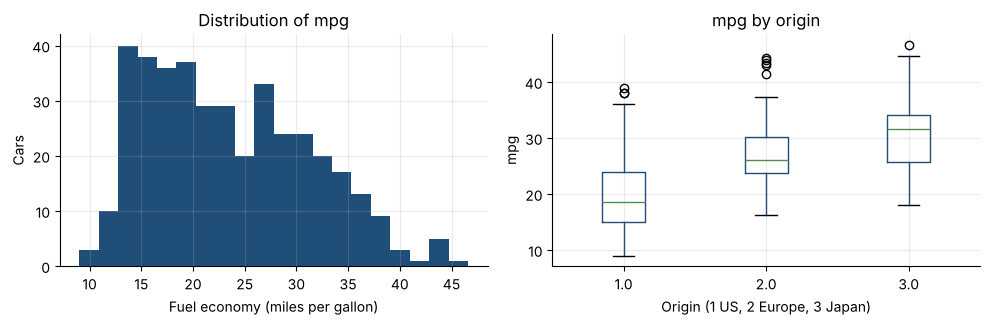

In [2]:
df = load_dataset("auto_mpg").frame
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["mpg"], bins=20); axes[0].set_xlabel("Fuel economy (miles per gallon)"); axes[0].set_ylabel("Cars"); axes[0].set_title("Distribution of mpg")
df.boxplot(column="mpg", by="origin", ax=axes[1]); axes[1].set_xlabel("Origin (1 US, 2 Europe, 3 Japan)"); axes[1].set_ylabel("mpg"); axes[1].set_title("mpg by origin"); fig.suptitle("")
plt.tight_layout(); plt.show()

## 2. Relationship: scatter plot with a trend line

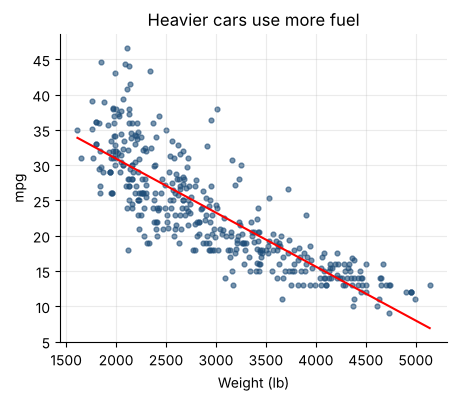

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(df["weight"], df["mpg"], s=12, alpha=0.6)
coef = np.polyfit(df["weight"], df["mpg"], 1)
xs = np.linspace(df["weight"].min(), df["weight"].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color="red"); ax.set_xlabel("Weight (lb)"); ax.set_ylabel("mpg"); ax.set_title("Heavier cars use more fuel")
plt.show()

## 3. Correlation heatmap

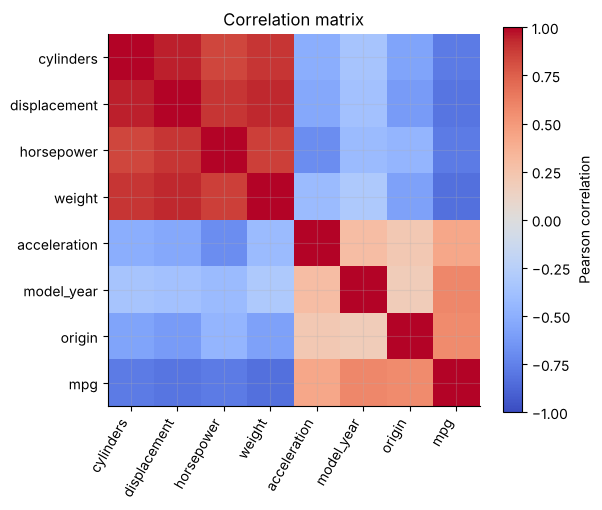

In [4]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
plt.colorbar(im, label="Pearson correlation"); ax.set_title("Correlation matrix"); plt.show()

## 4. A misleading axis

The same two bars look very different when the axis does not start at zero.

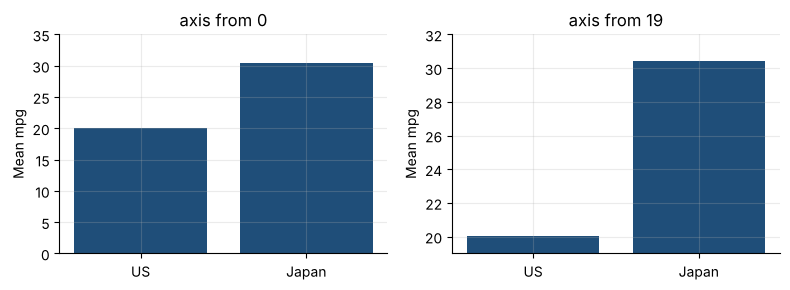

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
vals = [df[df.origin == 1]["mpg"].mean(), df[df.origin == 3]["mpg"].mean()]
for ax, lim in zip(axes, [(0, 35), (19, 32)]):
    ax.bar(["US", "Japan"], vals); ax.set_ylim(*lim); ax.set_ylabel("Mean mpg"); ax.set_title(f"axis from {lim[0]}")
plt.tight_layout(); plt.show()

## Exercises

1. Make a violin plot of `horsepower` by `cylinders` and describe what it adds to a box plot.
2. Find a pair of columns whose scatter plot shows a curve and plot it.

## Summary

- Pick the plot for the question.
- Always label units.
- Start bar axes at zero.

**Next:** Linear algebra.

**Data note.** Real datasets come from `ml_lab.data` with licence notes in `datasets/catalog`. Synthetic numbers appear only where a demonstration needs controlled data, and are labelled.